# 21.3 Value — What does **V** actually contain? 📦

We now have the complete attention trio:

$$
\boxed{Q,\ K,\ V}
$$

The easiest mental model is:

> 🔎 **Q asks:** “What am I looking for?”
> 🔑 **K matches:** “How relevant am I to that request?”
> 📦 **V provides:** “Here is the information you should actually retrieve.”

In the attention mechanism, the Query–Key interaction determines the weights, and those weights are then applied to the Values.    syllabus(20261018-070535)

---

## 1. What is the Value?

The **Value** is the actual information that attention retrieves and combines.

For an input representation $X$:

$$
\boxed{V = XW_V}
$$

For an individual token:

$$
\boxed{v_i=x_iW_V}
$$

where:

- $x_i$ = token/hidden representation
- $W_V$ = learned Value projection matrix
- $v_i$ = Value vector

So, just like the Key, the Value is a **learned projection** of the underlying representation.

---

# 2. Why do we need a separate Value?

This is the key idea.

Suppose the decoder asks:

> **“Which source information is relevant to what I'm generating?”**

The **Keys** help answer:

> “Which encoder positions are relevant?”

But after determining relevance, we need the **actual information from those positions**.

That's the job of the Values.
```text
             Query
               │
               ▼
        Compare with Keys
               │
               ▼
       Attention Weights
               │
               ▼
        Weight the Values
               │
               ▼
       Attention Output
```

So:

$$
\boxed{
Q,K \rightarrow \text{WHERE to look}
}
$$

$$
\boxed{
V \rightarrow \text{WHAT information to retrieve}
}
$$

---

# 3. The complete Q–K–V mechanism

Now combine everything you've learned.

Suppose we have:

$$
X
$$

The model creates three different projections:

$$
\boxed{Q=XW_Q}
$$

$$
\boxed{K=XW_K}
$$

$$
\boxed{V=XW_V}
$$

Then:

### Step 1 — Compare Query and Keys

$$
QK^T
$$

This gives relevance scores.

### Step 2 — Scale

$$
\frac{QK^T}{\sqrt{d_k}}
$$

### Step 3 — Softmax

$$
A=
\operatorname{softmax}
\left(
\frac{QK^T}{\sqrt{d_k}}
\right)
$$

These are the attention weights.

### Step 4 — Retrieve information from Values

$$
\boxed{
\text{Attention}(Q,K,V)
=
\operatorname{softmax}
\left(
\frac{QK^T}{\sqrt{d_k}}
\right)V
}
$$

This is the scaled dot-product attention equation from your syllabus.    syllabus(20261018-070535)

---

# 4. Why are Values weighted?

Imagine there are three source tokens:
```text
The     cat     eats
```

Suppose the decoder's current Query produces:

$$
\alpha=[0.1,\ 0.8,\ 0.1]
$$

That means:

- `"The"` → 10% contribution
- `"cat"` → 80% contribution
- `"eats"` → 10% contribution

Now suppose their Value vectors are:

$$
v_1,\ v_2,\ v_3
$$

The resulting context is:

$$
c=0.1v_1+0.8v_2+0.1v_3
$$

So the Value corresponding to `"cat"` contributes the most.

This is why attention can be viewed as a **weighted information retrieval mechanism**.

---

# 5. Key vs Value — the most important distinction ⚠️

This is worth memorizing.

| Component         | Main question                  | Role              |
| ----------------- | ------------------------------ | ----------------- |
| **Query $Q$**     | What am I looking for?         | Search/request    |
| **Key $K$**       | How relevant am I?             | Matching/index    |
| **Value $V$**     | What information do I provide? | Retrieved content |

So:
```text
Q ───────► asks
           │
           ▼
K ───────► matches
           │
           ▼
      attention weights
           │
           ▼
V ───────► provides information
```

### One-line intuition

> **Q finds, K matches, V informs.** 🎯

---

# 6. Why not simply use K as the Value?

Because **matching information** and **retrieved information** don't necessarily need to have the same representation.

The model therefore learns separate projections:

$$
W_K
$$

and

$$
W_V
$$

giving:

$$
K=XW_K
$$

$$
V=XW_V
$$

This lets the model learn:

- a representation useful for **determining relevance**, and
- a representation useful for **transmitting information**.

That's an important architectural idea.

---

# 7. Cross-Attention Example 🌐

This connects directly to your current **Seq2Seq → Attention** transition.

Suppose we're translating:

> **English:** “The cat eats fish”

into another language.

At some decoder step, the decoder has a Query $q_t$.

The encoder has produced:

$$
K=[k_1,k_2,k_3,k_4,k_5]
$$

and:

$$
V=[v_1,v_2,v_3,v_4,v_5]
$$

The decoder Query compares against every Key:

$$
q_tK^T
$$

Suppose the resulting attention weights are:

$$
[0.05,\ 0.70,\ 0.10,\ 0.05,\ 0.10]
$$

The model then computes:

$$
c_t=
0.05v_1+
0.70v_2+
0.10v_3+
0.05v_4+
0.10v_5
$$

The resulting $c_t$ is the **context/information retrieved from the encoder** for that decoding step.

Notice something important:

### The weights come from Q–K interaction.

But:

### The actual content comes from V.

That's the conceptual heart of attention.

---

# 8. Q, K, V in Cross-Attention

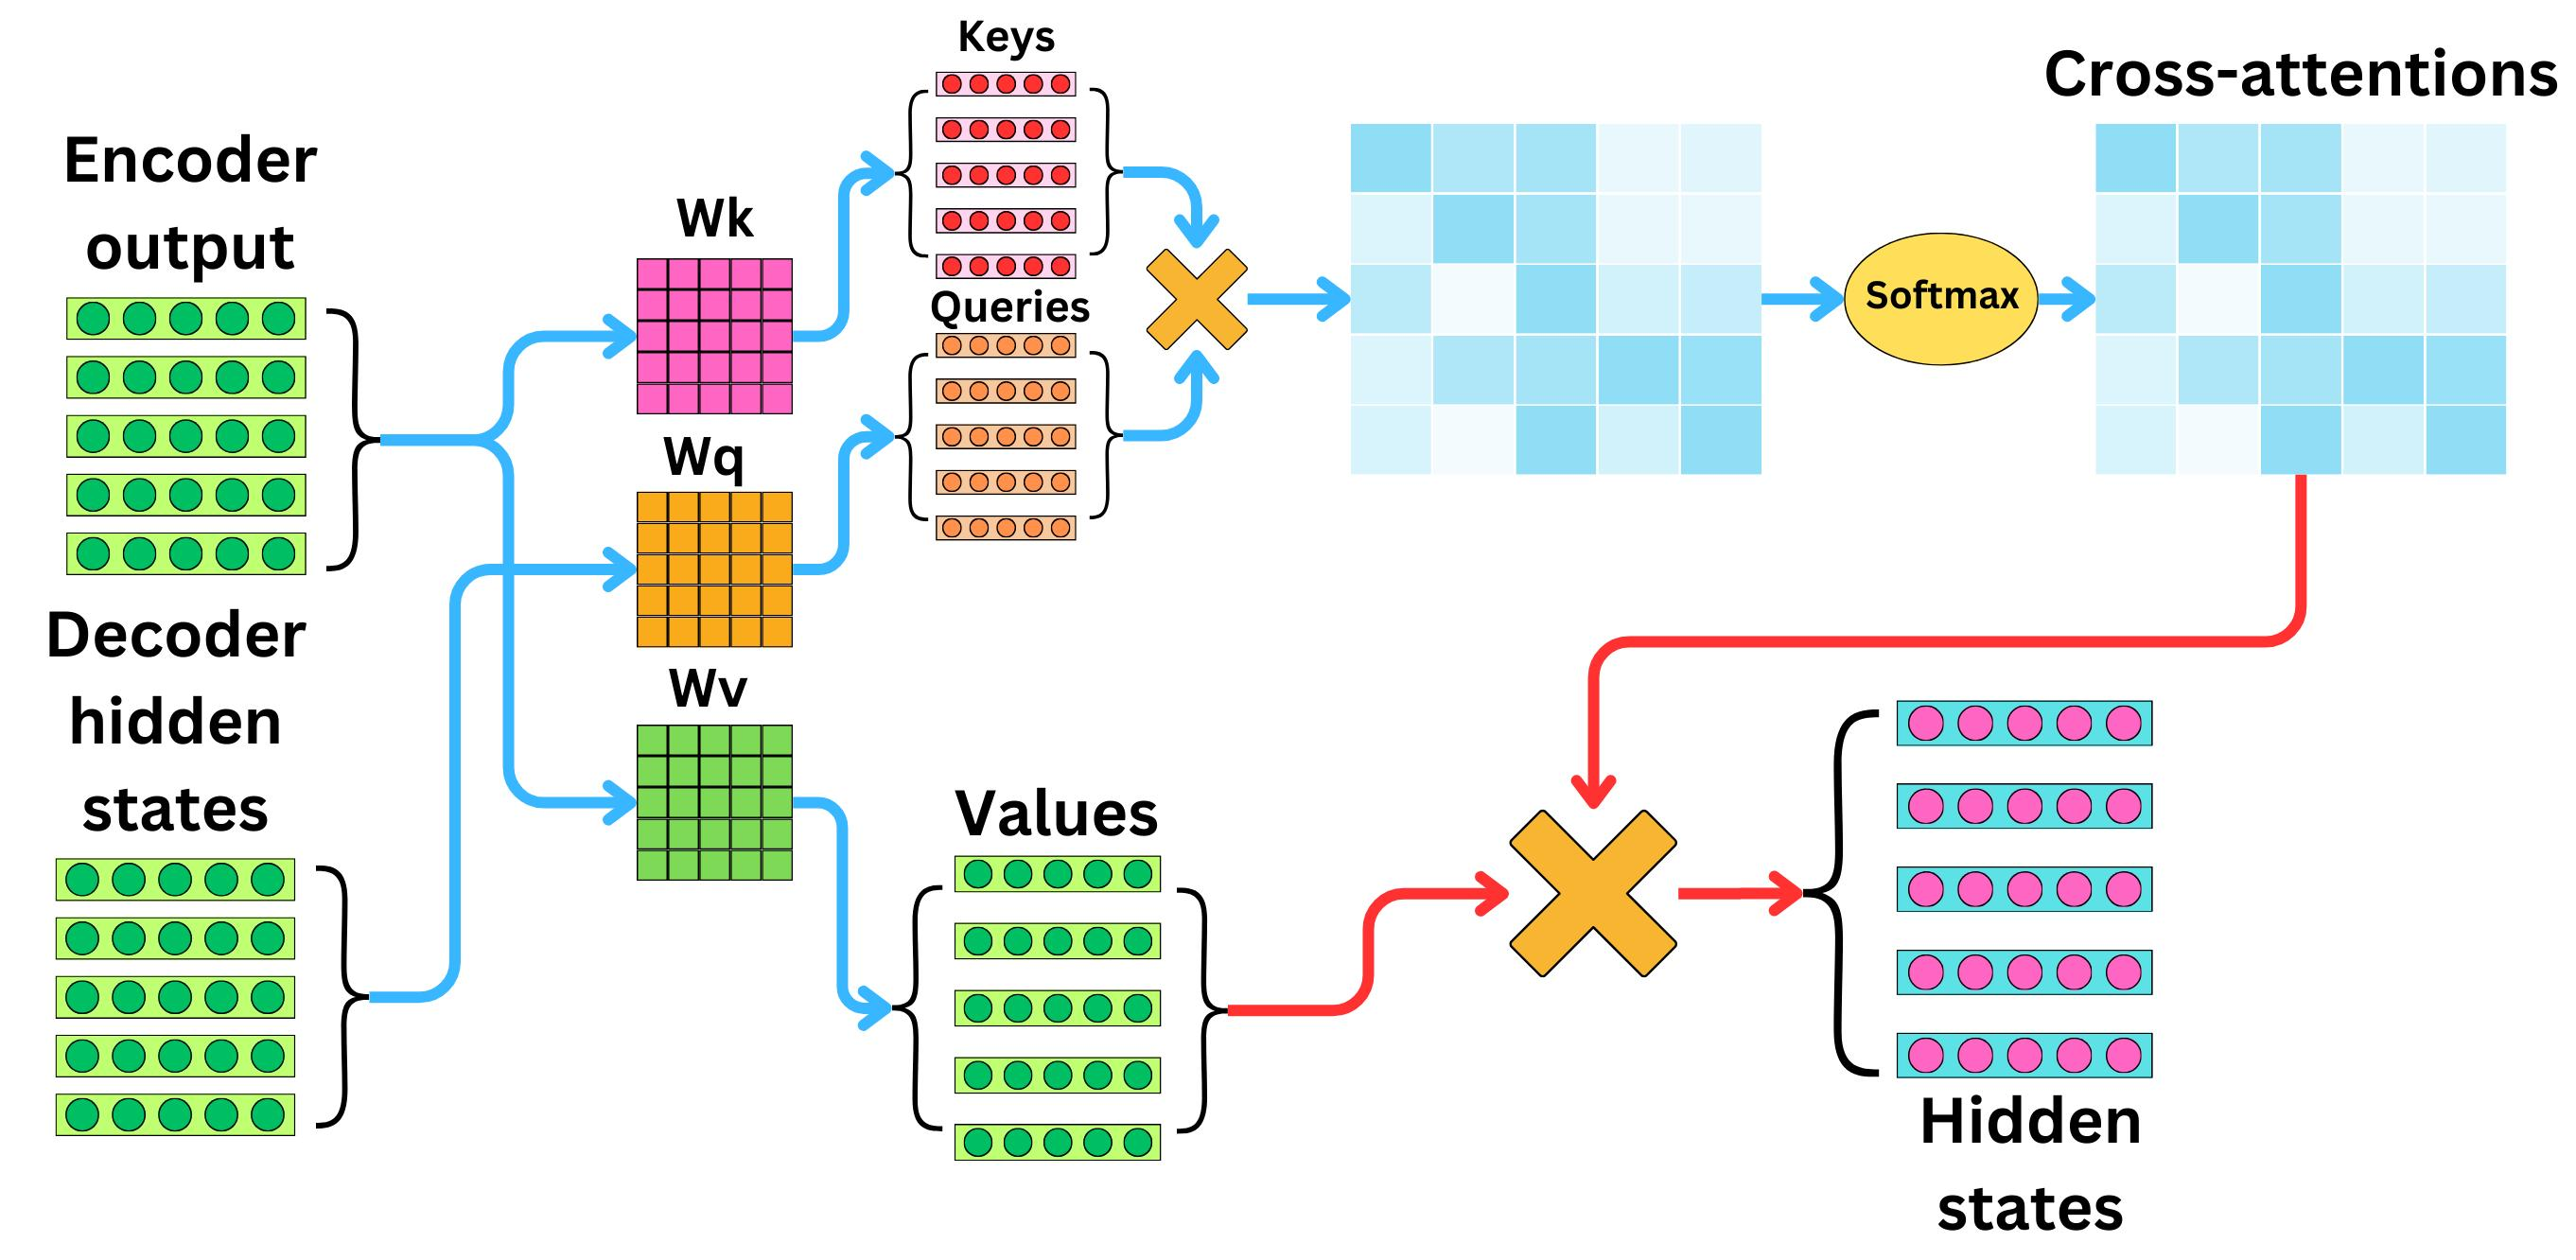

In encoder-decoder attention:
```text
                  ENCODER
             source sequence
                    │
             ┌──────┴──────┐
             ▼             ▼
             K             V
             │             │
             │             │
             └──────┬──────┘
                    │
              Attention
                    ▲
                    │
                    Q
                    │
                 DECODER
              target state
```

Therefore:

$$
\boxed{Q\leftarrow\text{Decoder}}
$$

$$
\boxed{K\leftarrow\text{Encoder}}
$$

$$
\boxed{V\leftarrow\text{Encoder}}
$$

This is the critical distinction between **self-attention** and **cross-attention**.

---

# 9. Q, K, V in Self-Attention

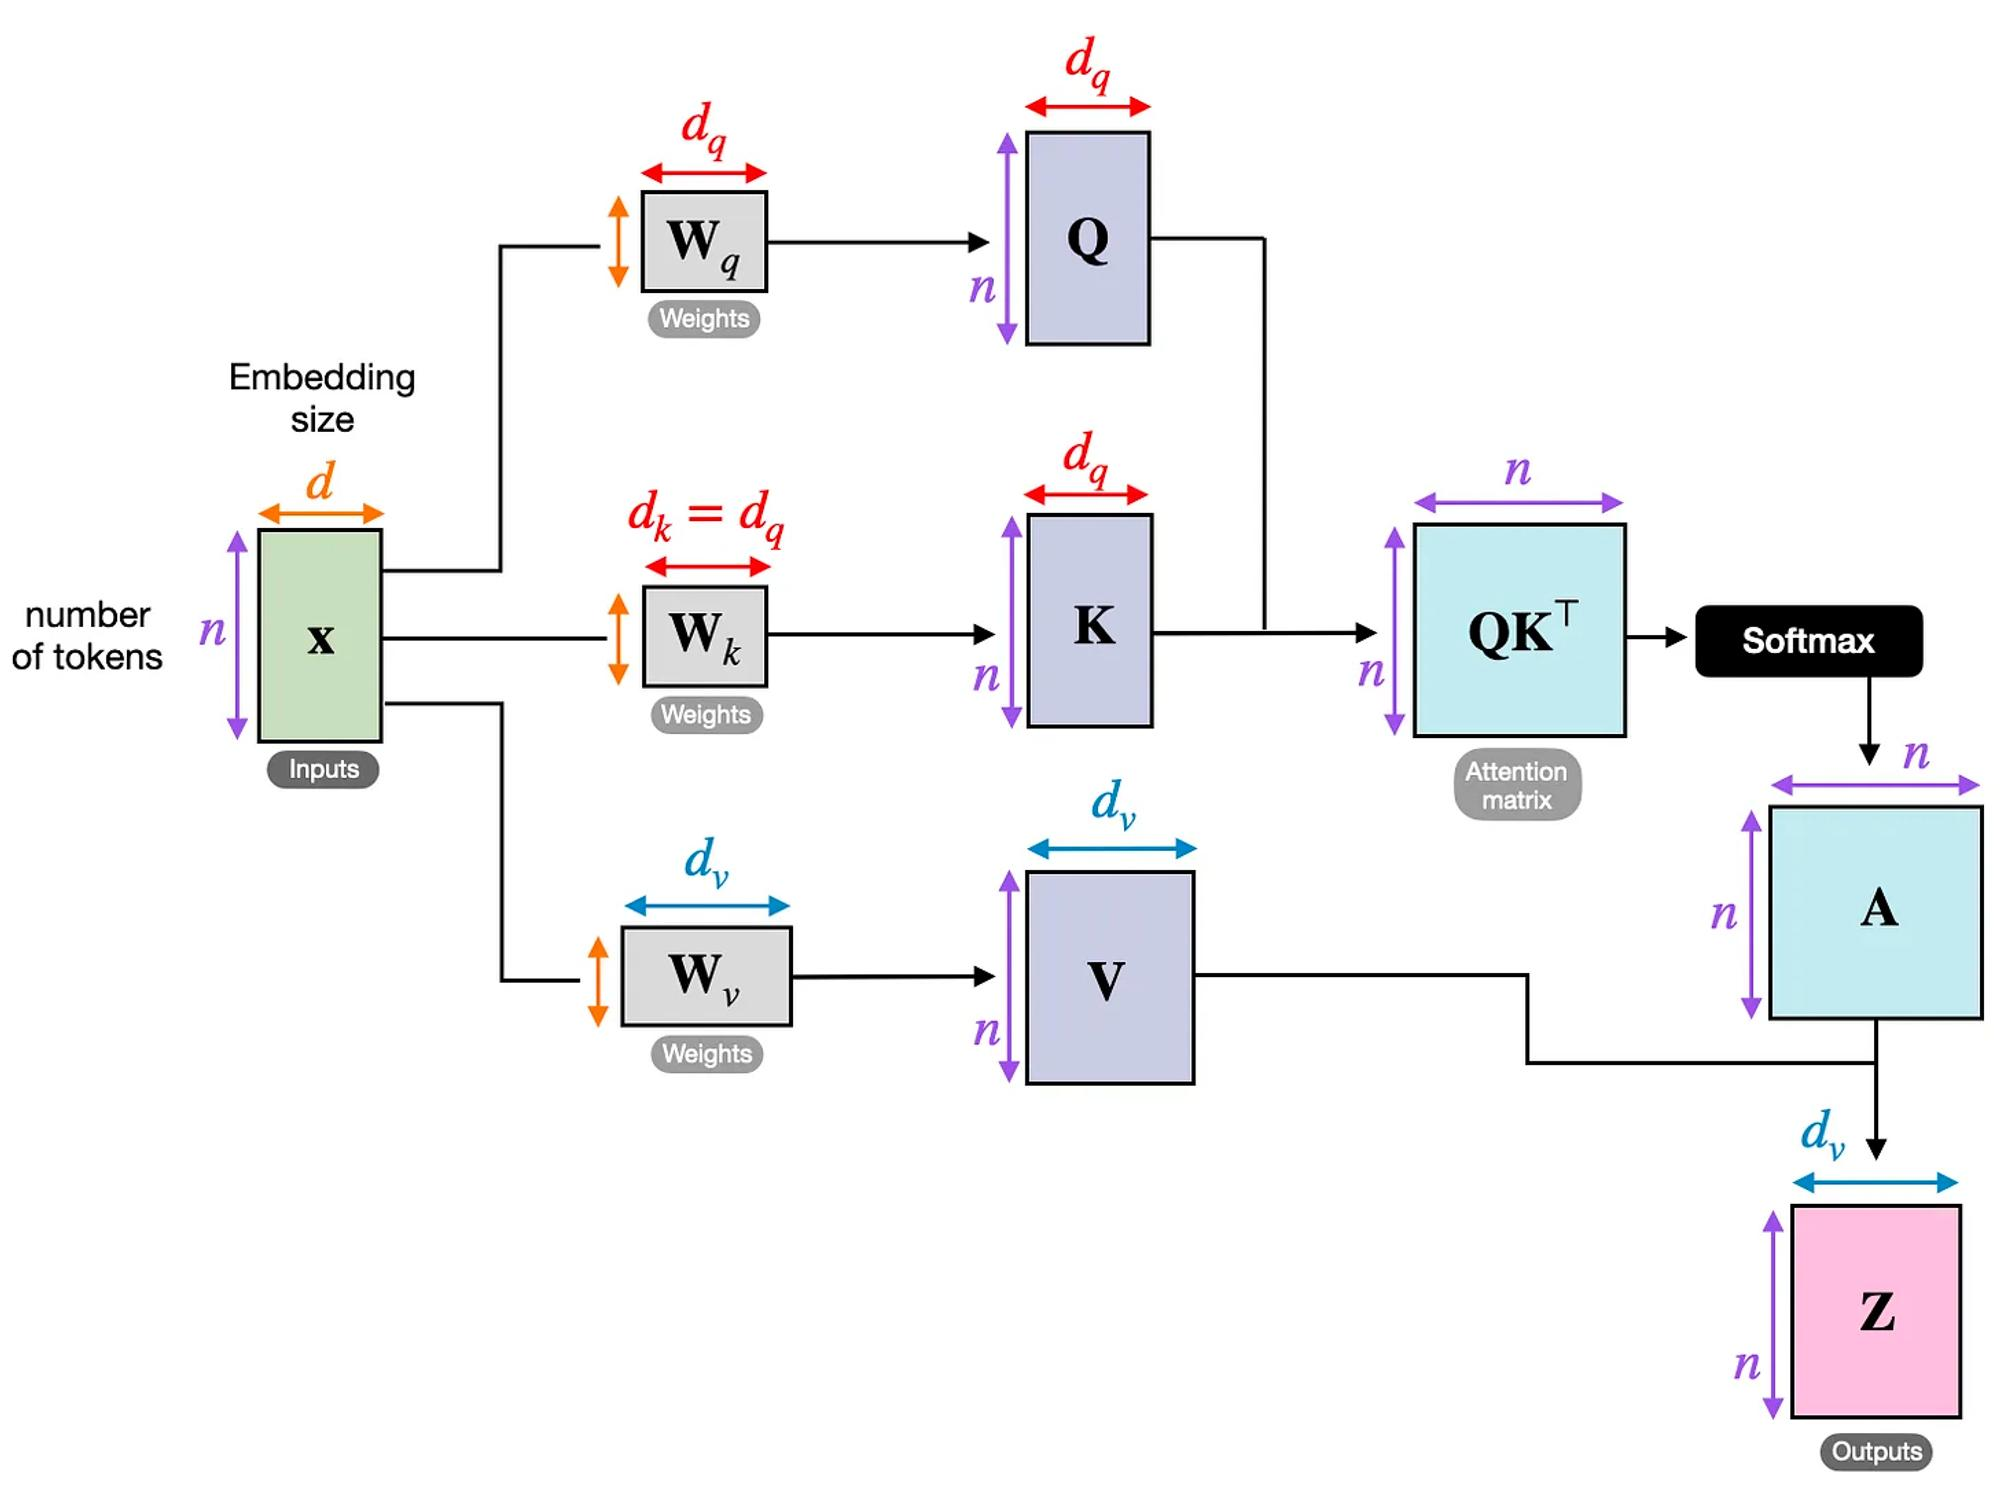

In self-attention, all three originate from the same sequence:

$$
Q=XW_Q
$$

$$
K=XW_K
$$

$$
V=XW_V
$$

So:
```text
             Same sequence X
                    │
          ┌─────────┼─────────┐
          ▼         ▼         ▼
          Q         K         V
          │         │         │
          └────┬────┘         │
               ▼              │
          QKᵀ → weights ──────┘
                         │
                         ▼
                    Weighted V
```

Your DL background already covers basic self-attention, so the important NLP-specific insight here is **what each projection is doing**, especially in encoder-decoder cross-attention.

---

# 10. Shape intuition 🧮

Suppose:

$$
X\in\mathbb{R}^{T\times d_{\text{model}}}
$$

and:

$$
W_V\in\mathbb{R}^{d_{\text{model}}\times d_v}
$$

Then:

$$
\boxed{V=XW_V}
$$

has shape:

$$
\boxed{V\in\mathbb{R}^{T\times d_v}}
$$

Meanwhile:

$$
QK^T
$$

produces attention scores.

If:

$$
Q\in\mathbb{R}^{T_q\times d_k}
$$

and:

$$
K\in\mathbb{R}^{T_k\times d_k}
$$

then:

$$
QK^T \in \mathbb{R}^{T_q\times T_k}
$$

and finally:

$$
(T_q\times T_k)(T_k\times d_v)
=
\boxed{T_q\times d_v}
$$

So the output has one resulting representation for each Query position.

This shape reasoning will become extremely important when we implement attention from scratch in **Module 22**.

---

# 11. The full mental model 🧠

Think of attention like a smart information desk:
```text
┌─────────────────────────────────────────────┐
│                  ATTENTION                  │
│                                             │
│  Q = "What do I need?"                     │
│                                             │
│  K = "What does each position represent    │
│       for matching?"                       │
│                                             │
│  Q × K = "How relevant is each position?" │
│                                             │
│  Softmax = "How much should I attend?"     │
│                                             │
│  V = "What information should I take?"    │
│                                             │
│  Weighted V = "Retrieved information"      │
└─────────────────────────────────────────────┘
```

And mathematically:

$$
\boxed{
Q,K \rightarrow \text{attention weights} \rightarrow V \rightarrow \text{output}
}
$$

---

# 🔥 Q–K–V in One Table

|             | Query             | Key               | Value                |
| ----------- | ----------------- | ----------------- | -------------------- |
| Symbol      | $Q$               | $K$               | $V$                  |
| Projection  | $XW_Q$            | $XW_K$            | $XW_V$               |
| Purpose     | Search            | Match             | Retrieve             |
| Used in     | Score calculation | Score calculation | Weighted sum         |
| Interaction | $QK^T$            | $QK^T$            | Weighed by attention |
| Intuition   | “What do I need?” | “Am I relevant?”  | “What do I contain?” |

### ⭐ Memorize this:

$$
\boxed{\textbf{Q asks → K matches → V provides}}
$$

---

## What you should remember 🧠

1. **Value contains the information that attention actually retrieves and combines.**
2. $V=XW_V$.
3. **Q and K determine attention weights.**
4. **Those weights are applied to V.**
5. $QK^T$ determines **where to look**; $V$ determines **what information comes back**.
6. In cross-attention: **Q = decoder, K/V = encoder**.
7. The complete mechanism is:

$$
\boxed{
\operatorname{Attention}(Q,K,V)
=
\operatorname{softmax}
\left(
\frac{QK^T}{\sqrt{d_k}}
\right)V
}
$$

---